# Random processes 3: Stochastic differential equations, options and magnets

*Learning path: random processes, part 3 of 3.* [Index](README.md) · Previous: [Random walks, Brownian motion and arrivals](02-random-walks-and-brownian-motion.ipynb)

In 1973 Fischer Black and Myron Scholes published a formula for the fair price of a stock option, and trading in
options exploded; Scholes and Robert Merton received the Nobel prize in economics for it. Their key step was to model
a stock price as a differential equation driven by Brownian motion. In physics, the same random forces explain why a
magnet loses its magnetism when it is heated past a sharp critical temperature. This lesson solves **stochastic
differential equations** numerically, prices an option two ways, and simulates the **Ising model** of a magnet.

**Who this is for.** Students who have done [lesson 2](02-random-walks-and-brownian-motion.ipynb) and know first-order
differential equations ([differential equations 1](../differential-equations/01-first-order-equations.ipynb)).

**What you will be able to do afterwards:**

1. write and simulate a stochastic differential equation with the Euler-Maruyama method;
2. recognise mean reversion (Ornstein-Uhlenbeck) and growth with noise (geometric Brownian motion);
3. price a European option by Monte Carlo simulation and by the Black-Scholes formula;
4. simulate the Ising model and locate its phase transition.

Plan about 60 minutes. Each section ends with a **Try this**; exercises, hints and answers are at the end.

## 1. Differential equations with noise

An ordinary differential equation $dx/dt = f(x, t)$ says how $x$ changes in a short time $dt$:
$dx = f(x, t)\,dt$. A **stochastic differential equation** adds a random kick proportional to an increment $dW$ of
Brownian motion:

$$dx = f(x, t)\,dt + g(x, t)\,dW.$$

$f$ is the **drift** and $g$ the **noise strength**. Since $dW$ has variance $dt$, its size is $\sqrt{dt}$, much larger
than $dt$ for small steps; that is what makes these equations different from ordinary ones. The simplest numerical
method, Euler-Maruyama (1955), steps

$$x \leftarrow x + f(x, t)\,\Delta t + g(x, t)\,\sqrt{\Delta t}\,Z, \qquad Z \text{ standard normal}.$$

`sde(f, g, x0, T, n)` does $n$ such steps from $x(0) = x_0$ up to time $T$; with a sixth argument it makes that many
paths, one per row.

## 2. Mean reversion: the Ornstein-Uhlenbeck process

A particle in a bowl is pulled back to the centre ($f = -x$) and kicked by noise ($g = 1/2$). Four paths from
$x_0 = 2$:

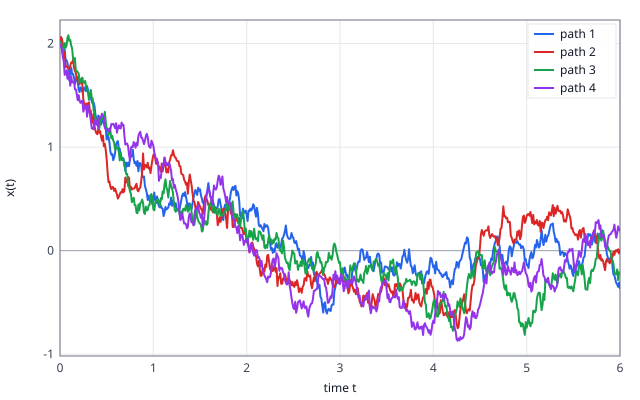

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [1]:
seed(3);
X = sde(-x, 1/2, 2, 6, 600, 4);
t = linspace(0, 6, 601);
p = legend(plot(t, X(1)), "path 1");
for k = 2:4
  p = show(p, legend(plot(t, X(k)), "path " + str(k)));
end
labels(p, "time t", "x(t)")

Without noise, $x = 2e^{-t}$ would slide to 0. With noise, each path relaxes towards 0 and then keeps fluctuating
around it. Leonard Ornstein and George Uhlenbeck (1930) found the balance: the spread settles at variance
$g^2/2 = 1/8$ for this equation (in general $g^2/(2\theta)$ for a pull $f = -\theta x$). The same model describes
interest rates (Vasicek) and the velocity of a Brownian particle.

In [2]:
seed(5);
Y = sde(-x, 1/2, 2, 5, 200, 3000);
eval(mean(column(Y, 201)), 3)
eval(var(column(Y, 201)), 3)

0.00663

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

0.120

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

**Try this.** Make the pull twice as strong, `sde(-2*x, 1/2, 2, 5, 200, 3000)`. What variance do you expect at the end?

## 3. Stock prices: geometric Brownian motion

A stock price $S$ grows at an average rate $\mu$ per year and fluctuates by a percentage, not a fixed amount: its noise
is proportional to $S$. So

$$dS = \mu S\,dt + \sigma S\,dW,$$

with **volatility** $\sigma$. Here are five possible years for a stock at 100 with $\mu = 5\%$ and $\sigma = 20\%$
(250 trading days):

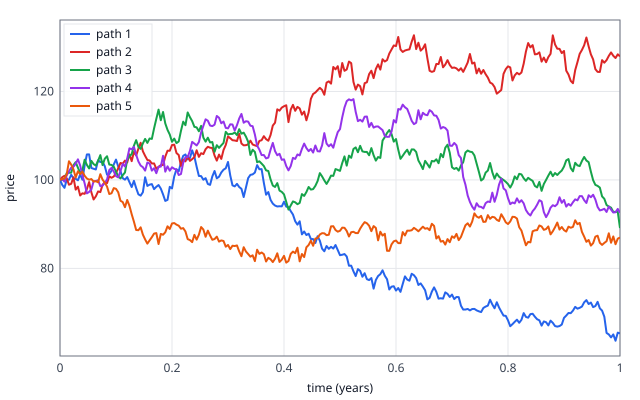

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [3]:
seed(7);
S = sde(0.05*x, 0.2*x, 100, 1, 250, 5);
t = linspace(0, 1, 251);
q = legend(plot(t, S(1)), "path 1");
for k = 2:5
  q = show(q, legend(plot(t, S(k)), "path " + str(k)));
end
labels(q, "time (years)", "price")

The exact solution is $S(t) = S_0\, e^{(\mu - \sigma^2/2)t + \sigma W(t)}$: the logarithm of the price is a Brownian
motion with drift, so prices are lognormal and never negative. Note the correction $-\sigma^2/2$: the typical (median)
price grows more slowly than the mean, an effect of the noise that ordinary calculus would miss (it comes from Itô's
lemma).

**Try this.** Simulate 5000 years and compare the mean of the final prices with $100 e^{0.05} \approx 105.1$, and their
median with $100 e^{0.05 - 0.02} \approx 103.0$.

## 4. Pricing an option two ways

A **call option** gives the right, not the obligation, to buy the stock in one year at the strike price $K = 100$.
At expiry it is worth $\max(S_T - K, 0)$. What is it worth today? Black and Scholes showed that the fair price is the
expected payoff discounted at the risk-free interest rate $r$, computed as if the stock grew at rate $r$ (the
"risk-neutral" world). With $r = 5\%$, simulate 5000 final prices and average the payoffs. The positive part
$\max(d, 0)$ of a list $d$ is $(d + |d|)/2$:

In [4]:
seed(8);
S = sde(0.05*x, 0.2*x, 100, 1, 50, 5000);
d = column(S, 51)' - 100;
eval(exp(-0.05) * mean((d + abs(d)) / 2), 4)

10.53

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

Black and Scholes solved the same problem exactly:

$$C = S_0 N(d_1) - K e^{-rT} N(d_2), \qquad d_{1,2} = \frac{\ln(S_0/K) + (r \pm \sigma^2/2)T}{\sigma\sqrt T},$$

where $N$ is the standard normal distribution function.

In [5]:
bscall(100, 100, 0.05, 0.2, 1)
bsput(100, 100, 0.05, 0.2, 1)

10.450583572185565

> Black-Scholes: d1 = 0.3500, d2 = 0.1500; call = S N(d1) - K e^(-rT) N(d2), put = K e^(-rT) N(-d2) - S N(-d1); call - put = S - K e^(-rT) (put-call parity)

5.573526022256971

> Black-Scholes: d1 = 0.3500, d2 = 0.1500; call = S N(d1) - K e^(-rT) N(d2), put = K e^(-rT) N(-d2) - S N(-d1); call - put = S - K e^(-rT) (put-call parity)

The simulation agrees to within its error, which shrinks like $1/\sqrt{\text{paths}}$. Monte Carlo pricing is slower,
but it works for options with no formula, for example options that depend on the whole path. A **put** (the right to
sell) is worth less here; the two prices satisfy put-call parity, $C - P = S_0 - K e^{-rT}$.

**Try this.** Double the volatility to $\sigma = 0.4$. How does the call price change, and why does more uncertainty
make an option more valuable?

## 5. A magnet: the Ising model

Wilhelm Lenz and his student Ernst Ising (1925) modelled a magnet as a grid of tiny arrows (spins) that point up
($+1$) or down ($-1$). Neighbouring spins prefer to agree; heat makes them flip at random. At temperature $T$ a
configuration with energy $E = -\sum_{\text{neighbours}} s_i s_j$ has probability proportional to $e^{-E/T}$.

The **Metropolis algorithm** (1953) samples from this distribution with a Markov chain: pick a spin, compute the energy
change $\Delta E$ of flipping it, flip if $\Delta E \le 0$, and otherwise flip with chance $e^{-\Delta E/T}$. The chain's
stationary distribution is exactly the one we want (lesson 1), so long runs give averages. `ising(n, T, sweeps)`
simulates an $n \times n$ grid and reports the average magnetization per spin `m` and energy per spin `e`:

In [6]:
seed(1);
r = ising(24, 1.5, 400);
r.m
r = ising(24, 3.5, 400);
r.m

0.9867187500000001
0.08991319444444441

Cold, the spins line up ($m \approx 1$): a magnet. Hot, they point every which way ($m \approx 0$). In between there is a
sharp change. Let us scan the temperature:

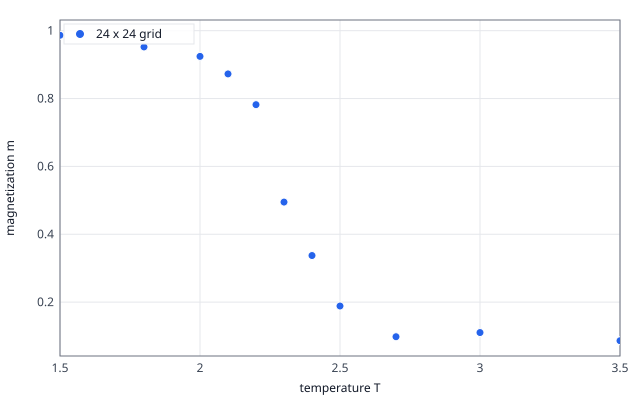

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [7]:
Ts = [1.5 1.8 2.0 2.1 2.2 2.3 2.4 2.5 2.7 3.0 3.5];
ms = zeros(1, 11);
seed(2);
for k = 1:11
  r = ising(24, Ts(k), 400);
  ms(k) = r.m;
end
labels(legend(scatter(Ts, ms), "24 x 24 grid"), "temperature T", "magnetization m")

The magnetization collapses near $T \approx 2.27$. Lars Onsager solved the model exactly in 1944, one of the
landmarks of mathematical physics: the critical temperature is

$$T_c = \frac{2}{\ln(1 + \sqrt 2)} \approx 2.269.$$

On a finite grid the drop is smoothed out; on an infinite grid it is a true **phase transition**, like water boiling.

**Try this.** Repeat the scan with a $12 \times 12$ grid and with $40 \times 40$ (fewer sweeps for speed). Which grid
shows the sharper drop?

## Summary

* A stochastic differential equation $dx = f\,dt + g\,dW$ adds Brownian noise to an ordinary one; Euler-Maruyama steps
  $x \leftarrow x + f\Delta t + g\sqrt{\Delta t}\,Z$.
* Ornstein-Uhlenbeck: pulled back to a mean, with a steady spread $g^2/(2\theta)$.
* Geometric Brownian motion models prices; the noise lowers the typical growth rate by $\sigma^2/2$.
* An option price is a discounted expected payoff: by simulation, or exactly by Black-Scholes.
* The Ising model, simulated by the Metropolis Markov chain, loses its magnetization at Onsager's $T_c \approx 2.269$.

This is the end of the random processes path. `help("stationary")`, `help("sde")` and `help("ising")` describe the
commands.

## Exercises

1. **Pure noise.** `sde(0, 1, 0, 1, 100, 2000)` is Brownian motion. Check that the final values have variance 1.
2. **Population with noise.** Simulate logistic growth with noise, $dx = x(1 - x)\,dt + 0.1\,x\,dW$ from $x_0 = 0.1$
   over 10 years. Plot a few paths. Where do they end up?
3. **Put by simulation.** Price the put of section 4 by Monte Carlo, with payoff $\max(K - S_T, 0)$, and compare with
   `bsput`.
4. **Put-call parity.** Check $C - P = S_0 - K e^{-rT}$ with `bscall` and `bsput` for $S_0 = 90$, $K = 100$.
5. **Energy.** In the Ising model, `r.e` is the energy per spin. Plot it against temperature. Where does it change
   fastest?

## Hints and answers

* **Section 2, Try this.** $g^2/(2\theta) = (1/4)/4 = 1/16 \approx 0.06$.
* **Section 3, Try this.** Use `sde(0.05*x, 0.2*x, 100, 1, 50, 5000)`, `mean` and `median` of the last column: about
  105 and 103.
* **Section 4, Try this.** About 18.0 instead of 10.45: the payoff is never negative, so wider swings add to the upside
  without adding to the downside.
* **Section 5, Try this.** The larger grid: finite-size rounding shrinks as $n$ grows.
* **Exercise 1.** About 1.
* **Exercise 2.** Near 1, the carrying capacity, fluctuating a little around it.
* **Exercise 3.** Use `d = 100 - column(S, 51)'` and the same positive-part formula; about 5.57.
* **Exercise 4.** Both sides are $90 - 100e^{-0.05} \approx -5.12$.
* **Exercise 5.** The energy per spin rises from $-2$ (all aligned) and changes fastest near $T_c$: the specific heat
  peaks there.

## Sources

1. F. Black and M. Scholes, "The pricing of options and corporate liabilities", *Journal of Political Economy* 81
   (1973) 637–654.
2. G. Maruyama, "Continuous Markov processes and stochastic equations", *Rendiconti del Circolo Matematico di Palermo*
   4 (1955) 48–90.
3. G. E. Uhlenbeck and L. S. Ornstein, "On the theory of the Brownian motion", *Physical Review* 36 (1930) 823–841.
4. N. Metropolis, A. W. Rosenbluth, M. N. Rosenbluth, A. H. Teller and E. Teller, "Equation of state calculations by
   fast computing machines", *Journal of Chemical Physics* 21 (1953) 1087–1092.
5. L. Onsager, "Crystal statistics. I. A two-dimensional model with an order-disorder transition", *Physical Review*
   65 (1944) 117–149.
6. D. J. Higham, "An algorithmic introduction to numerical simulation of stochastic differential equations", *SIAM
   Review* 43 (2001) 525–546.